## Procesamiento de Datos con Pandas

In [1]:
# modulos y datos

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
# cargar el dataset
retail = pd.read_excel("../data/online_retail_II.xlsx")
retail

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
...,...,...,...,...,...,...,...,...
525456,538171,22271,FELTCRAFT DOLL ROSIE,2,2010-12-09 20:01:00,2.95,17530.0,United Kingdom
525457,538171,22750,FELTCRAFT PRINCESS LOLA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom
525458,538171,22751,FELTCRAFT PRINCESS OLIVIA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom
525459,538171,20970,PINK FLORAL FELTCRAFT SHOULDER BAG,2,2010-12-09 20:01:00,3.75,17530.0,United Kingdom


In [12]:
retail.info()

<class 'pandas.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[us]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 32.1+ MB


### Valores faltantes

In [13]:
retail.isnull().sum()

Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64

In [16]:
# porcentaje de valores faltantes
(retail.isnull().sum() / len(retail) * 100).sort_values(ascending=False).round(2)

Customer ID    20.54
Description     0.56
StockCode       0.00
Invoice         0.00
Quantity        0.00
InvoiceDate     0.00
Price           0.00
Country         0.00
dtype: float64

## Estudio descriptivo de los datos

### Analisis Univariado

#### **Variables Numericas**

In [19]:
retail.info()

<class 'pandas.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[us]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 32.1+ MB


In [ ]:
num_vars = list(retail.select_dtypes(['int64', 'float64']).columns)

print('Estadisticas Descriptivas')
print(retail[num_vars].describe().round(2))

Estadisticas Descriptivas
        Quantity      Price  Customer ID
count  525461.00  525461.00    417534.00
mean       10.34       4.69     15360.65
std       107.42     146.13      1680.81
min     -9600.00  -53594.36     12346.00
25%         1.00       1.25     13983.00
50%         3.00       2.10     15311.00
75%        10.00       4.21     16799.00
max     19152.00   25111.09     18287.00


In [34]:
print('Deteccion de valores problematicos')
print("Valores negativos en Quantity : ",(retail['Quantity'] < 0).sum())
print("Valores cero en Quantity : ",(retail['Quantity'] == 0).sum())
print("Valores negativos en Price : ",(retail['Price'] < 0).sum())
print("Valores cero en Price : ",(retail['Price'] == 0).sum())

Deteccion de valores problematicos
Valores negativos en Quantity :  12326
Valores cero en Quantity :  0
Valores negativos en Price :  3
Valores cero en Price :  3687


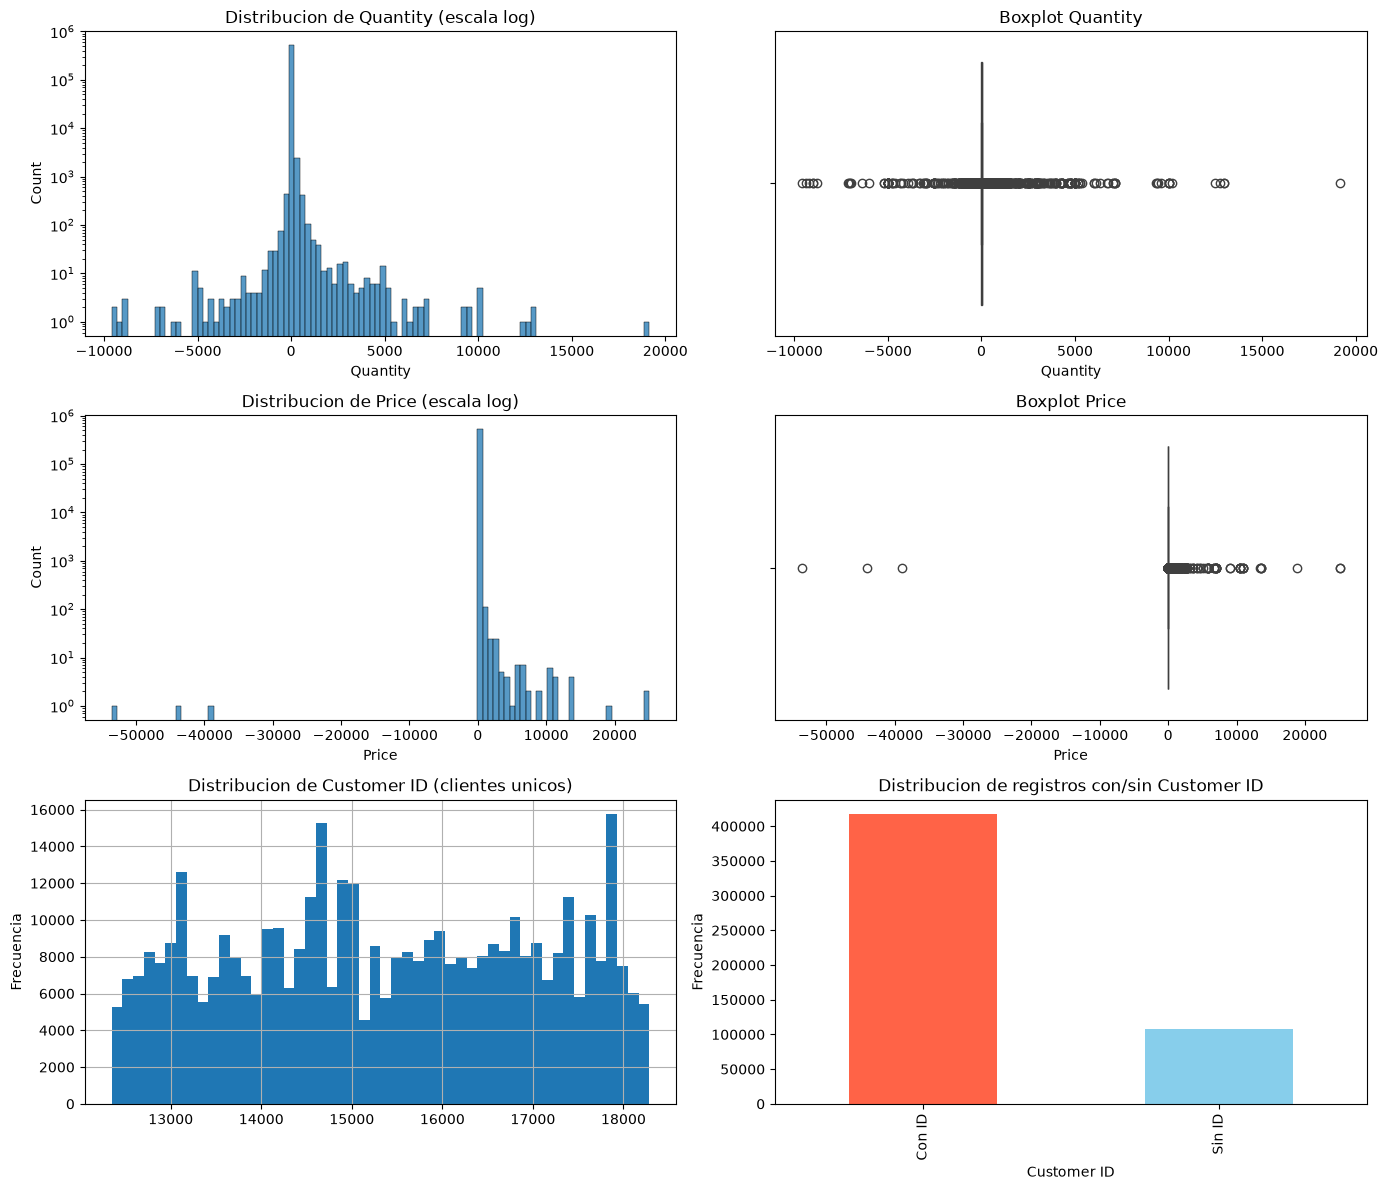

In [52]:
# Visualizacion

# Un plot, ventana, lienzo (fig) y un conjunto de 3X2 (axes)
fig, axes = plt.subplots(nrows=3, ncols=2, figsize = (14,12))

# Quantity: histograma y boxplot
sns.histplot(retail['Quantity'], bins=100, ax=axes[0,0], kde=False)
axes[0,0].set_title('Distribucion de Quantity (escala log)')
axes[0,0].set_yscale('log')

sns.boxplot(x=reatail['Quantity'], ax=axes[0,1])
axes[0,1].set_title('Boxplot Quantity')

# Price: histograma y boxplot
sns.histplot(retail['Price'], bins=100, ax=axes[1,0], kde=False)
axes[1,0].set_title('Distribucion de Price (escala log)')
axes[1,0].set_yscale('log')

sns.boxplot(x=reatail['Price'], ax=axes[1,1])
axes[1,1].set_title('Boxplot Price')

# Customer ID: Histograma y la distribucion de nulos
retail['Customer ID'].dropna().hist(bins=50, ax=axes[2,0])
axes[2,0].set_title('Distribucion de Customer ID (clientes unicos)')
axes[2,0].set_ylabel('Frecuencia')

null_status = reatail['Customer ID'].isnull().map({True: 'Sin ID', False: 'Con ID'})
null_status.value_counts().plot(kind='bar', ax=axes[2,1], color=['tomato', 'skyblue'])
axes[2,1].set_title('Distribucion de registros con/sin Customer ID')
axes[2,1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

### Variables Categoricas

In [55]:
retail.info()

<class 'pandas.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[us]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 32.1+ MB


In [60]:
cat_vars = list(retail.select_dtypes(['object']).columns)
cat_vars

C:\Users\Instructor\AppData\Local\Temp\ipykernel_32764\289246202.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_vars = list(retail.select_dtypes(['object']).columns)


['Invoice', 'StockCode', 'Description', 'Country']

In [65]:
# Country
print('Top 10 de paises por volumen de transaccion')
print(retail['Country'].value_counts().head(10))

Top 10 de paises por volumen de transaccion
Country
United Kingdom     485852
EIRE                 9670
Germany              8129
France               5772
Netherlands          2769
Spain                1278
Switzerland          1187
Portugal             1101
Belgium              1054
Channel Islands       906
Name: count, dtype: int64


In [83]:
# StockCode
print('Top 10 StockCode mas frecuentes')
print(retail['StockCode'].value_counts().head(10))

print('Total de StockCode unicos')
print(retail['StockCode'].unique())

Top 10 StockCode mas frecuentes
StockCode
85123A    3516
22423     2221
85099B    2057
21212     1933
21232     1843
20725     1620
84879     1458
84991     1400
21754     1386
20914     1276
Name: count, dtype: int64
Total de StockCode unicos
[85048 '79323P' '79323W' ... 22935 22933 21120]


In [75]:
# consideramos reconocer a las cancelaciones como aquellas cuyo StockCode
# termna en el caracter ^C
print('Numero de cancelaciones ',reatail['StockCode'].str.contains("^C", regex=True).sum())

Numero de cancelaciones  139


In [87]:
# Invoice
print('Top 10 Invoice mas frecuentes ',retail['Invoice'].value_counts().head(10))

print('Total de Invoice unicos ', retail['Invoice'].nunique())
print('Invoice con C (canelaciones)',retail['Invoice'].str.contains("^C", regex=True).sum())

Top 10 Invoice mas frecuentes  Invoice
537434    675
538071    652
537638    601
537237    597
536876    593
536592    592
537823    591
536031    582
490074    580
491966    579
Name: count, dtype: int64
Total de Invoice unicos  28816
Invoice con C (canelaciones) 10206


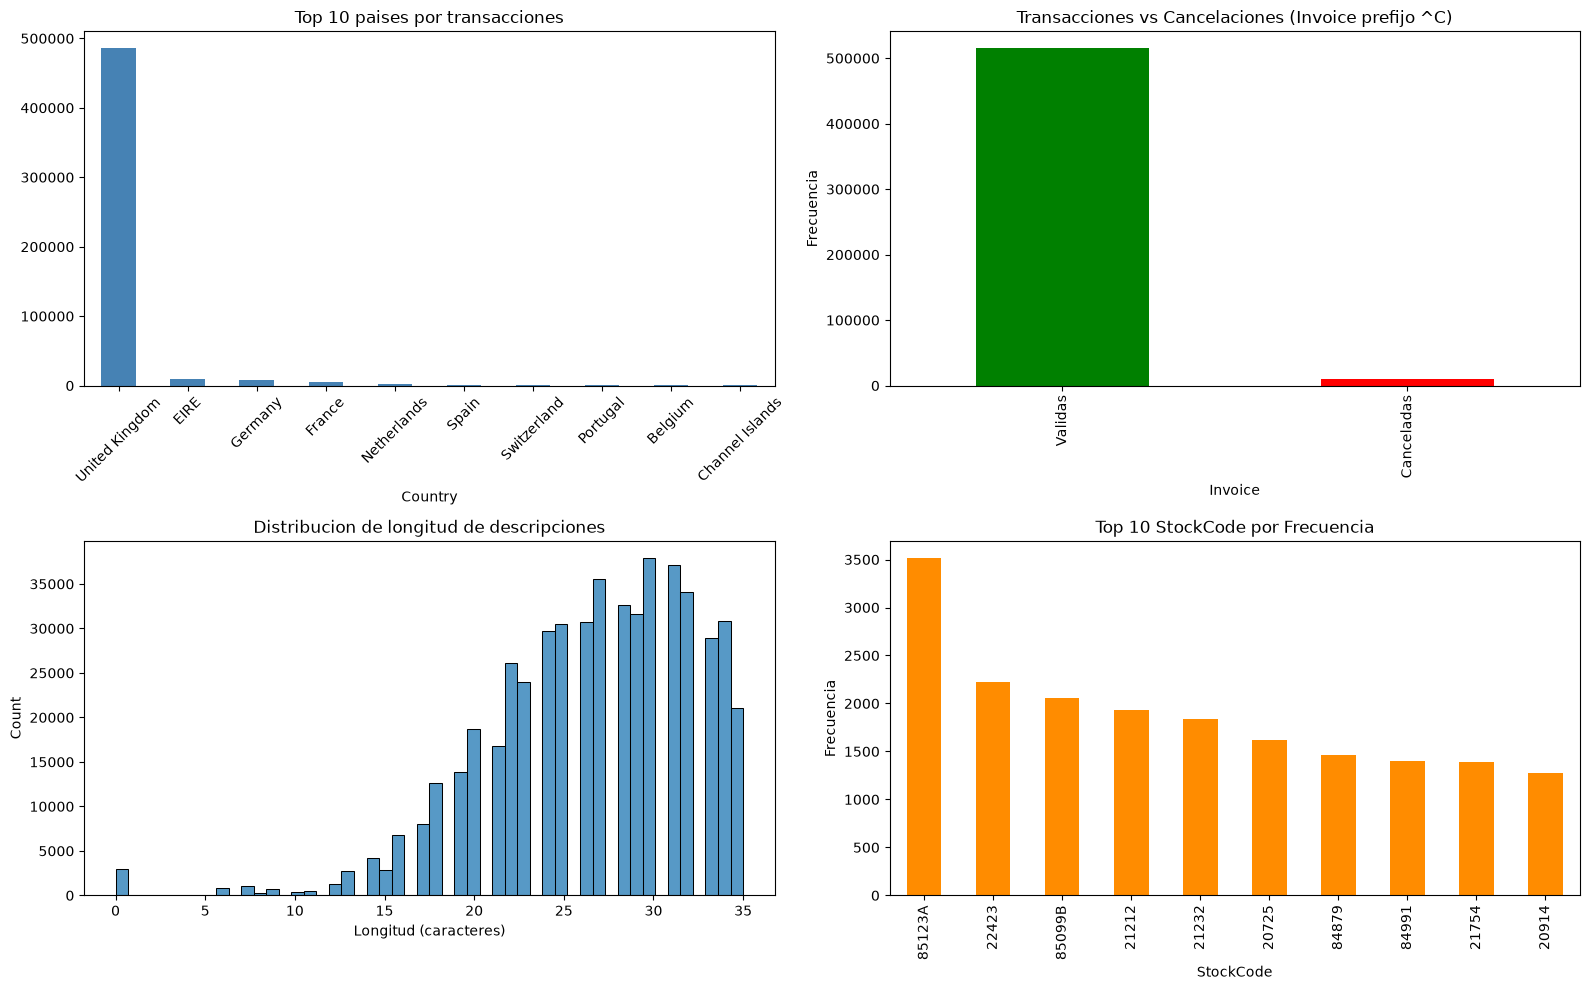

In [101]:
# Visualizacion de la informacion categorica
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16,10))

# Top paises
top_countres = retail['Country'].value_counts().head(10)
top_countres.plot(kind='bar', ax=axes[0,0], color='steelblue')
axes[0,0].set_title('Top 10 paises por transacciones')
axes[0,0].tick_params(axis='x', rotation=45)

# Distribucion de cancelacion en Invoice
cancelations = retail['Invoice'].astype(str).str.contains("^C", regex=True).value_counts()
cancelations.plot(kind='bar', ax=axes[0,1], color=['green', 'red'])
axes[0,1].set_title('Transacciones vs Cancelaciones (Invoice prefijo ^C)')
axes[0,1].set_xticklabels(['Validas', 'Canceladas'])
axes[0,1].set_ylabel('Frecuencia')

# Longitud de descripcciones (para detectar patrones)
retail['desc_len'] = retail['Description'].fillna("").str.len()
sns.histplot(retail['desc_len'], bins=50, ax=axes[1,0])
axes[1,0].set_title('Distribucion de longitud de descripciones')
axes[1,0].set_xlabel('Longitud (caracteres)')

# StockCode: top 10
top_stock = retail['StockCode'].value_counts().head(10)
top_stock.plot(kind='bar', ax=axes[1,1], color='darkorange')
axes[1,1].set_title('Top 10 StockCode por Frecuencia')
axes[1,1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()